In [9]:
import pandas as pd
nist_spectra_df = pd.read_pickle('../../data/proc/nist23/spec_df.pkl')
nist_spectra_df

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ramped,stepped,has_ace,has_nce
0,0,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461655,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,False,True
1,1,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461656,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,False,True
2,2,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461657,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,False,True
3,3,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461658,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,False,True
4,4,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461659,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1899592,1899587,12331,[M+H]+,FT,HCD,MS2,P,mona23,AC000010,NaN,...,NaN,370611,NaN,NaN,NaN,NaN,False,False,False,True
1899593,1899588,12331,[M+H]+,FT,HCD,MS2,P,mona23,AC000009,NaN,...,NaN,370611,NaN,NaN,NaN,NaN,False,False,False,True
1899594,1899589,12331,[M+H]+,FT,HCD,MS2,P,mona23,AC000008,NaN,...,NaN,370611,NaN,NaN,NaN,NaN,False,False,False,True
1899595,1899590,12331,[M+H]+,FT,HCD,MS2,P,mona23,AC000007,NaN,...,NaN,370611,NaN,NaN,NaN,NaN,False,False,False,True


In [10]:
nist_spectra_df = nist_spectra_df[nist_spectra_df['dset'].isin(['nist23_hr1', 'nist23_hr2'])]
nist_spectra_df.shape

(1754467, 25)

In [11]:
nist_spectra_df['ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500, 0), axis=1)

/tmp/ipykernel_3779674/1389500530.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nist_spectra_df['ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500, 0), axis=1)


In [12]:
# Group by both prec_type and inst_type
prec_inst_counts = nist_spectra_df.groupby(['prec_type', 'inst_type']).size().reset_index(name='count')

# Create a pivot table for better visualization
prec_inst_pivot = prec_inst_counts.pivot_table(index='prec_type', columns='inst_type', values='count', fill_value=0)

# Display the top 20 adduct types by total count
total_by_prec = prec_inst_pivot.sum(axis=1).sort_values(ascending=False)
top_20_prec_types = total_by_prec.head(20).index

print("Top 20 adduct types by instrument type:")
print("="*60)
display(prec_inst_pivot.loc[top_20_prec_types])

# Show summary statistics
print(f"\nSummary:")
print(f"Total unique adduct types: {len(prec_inst_pivot)}")
print(f"Total unique instrument types: {len(prec_inst_pivot.columns)}")
print(f"\nInstrument types available:")
for inst_type in prec_inst_pivot.columns:
    total_spectra = prec_inst_pivot[inst_type].sum()
    print(f"  {inst_type}: {total_spectra:,} spectra")

Top 20 adduct types by instrument type:


inst_type,FT,QTOF
prec_type,,
[M+H]+,508978.0,20073.0
[M-H]-,180250.0,2197.0
[M+H-H2O]+,118306.0,3443.0
[2M+H]+,59355.0,2877.0
[M+Na]+,60808.0,926.0
[M+H+2i]+,47727.0,0.0
[2M-H]-,45110.0,797.0
[M+H-NH3]+,27052.0,662.0
[M+H-2H2O]+,22963.0,0.0



Summary:
Total unique adduct types: 27022
Total unique instrument types: 2

Instrument types available:
  FT: 1,719,745.0 spectra
  QTOF: 34,722.0 spectra


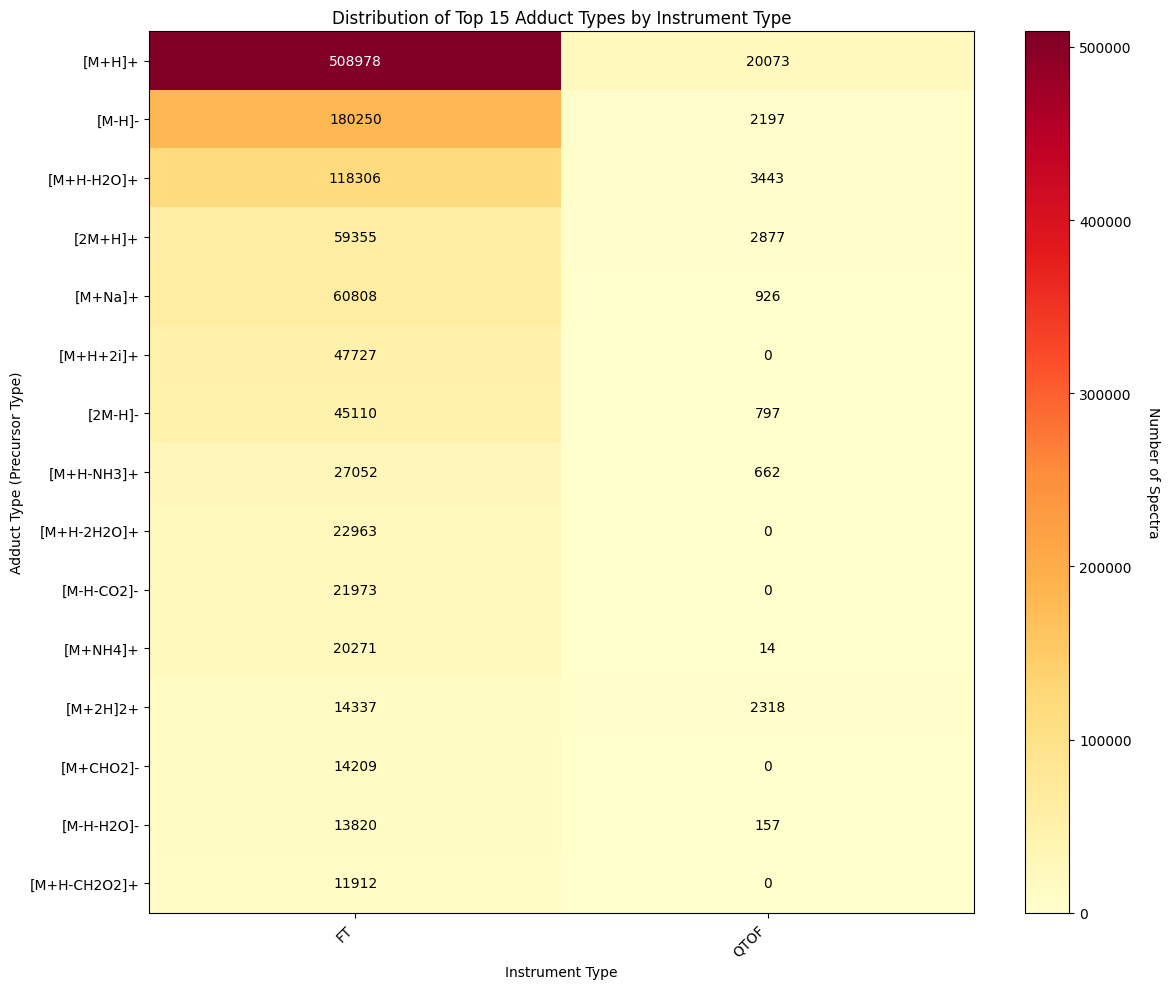


Percentage distribution by instrument type for top 10 adduct types:


inst_type,FT,QTOF
prec_type,,
[M+H]+,96.2,3.8
[M-H]-,98.8,1.2
[M+H-H2O]+,97.2,2.8
[2M+H]+,95.4,4.6
[M+Na]+,98.5,1.5
[M+H+2i]+,100.0,0.0
[2M-H]-,98.3,1.7
[M+H-NH3]+,97.6,2.4
[M+H-2H2O]+,100.0,0.0


In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Create a heatmap for the top 15 adduct types using matplotlib
top_15_prec_types = total_by_prec.head(15).index
heatmap_data = prec_inst_pivot.loc[top_15_prec_types]

fig, ax = plt.subplots(figsize=(12, 10))

# Create the heatmap using imshow
im = ax.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto')

# Set ticks and labels
ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_xticklabels(heatmap_data.columns, rotation=45, ha='right')
ax.set_yticklabels(heatmap_data.index)

# Add text annotations
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        text = ax.text(j, i, int(heatmap_data.iloc[i, j]),
                      ha="center", va="center", color="black" if heatmap_data.iloc[i, j] < heatmap_data.values.max()/2 else "white")

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Number of Spectra', rotation=270, labelpad=20)

# Set labels and title
ax.set_title('Distribution of Top 15 Adduct Types by Instrument Type')
ax.set_xlabel('Instrument Type')
ax.set_ylabel('Adduct Type (Precursor Type)')

plt.tight_layout()
plt.show()

# Show the percentage distribution for each adduct type
print("\nPercentage distribution by instrument type for top 10 adduct types:")
print("="*70)
top_10_prec_types = total_by_prec.head(10).index
percentage_data = prec_inst_pivot.loc[top_10_prec_types].div(prec_inst_pivot.loc[top_10_prec_types].sum(axis=1), axis=0) * 100
display(percentage_data.round(1))

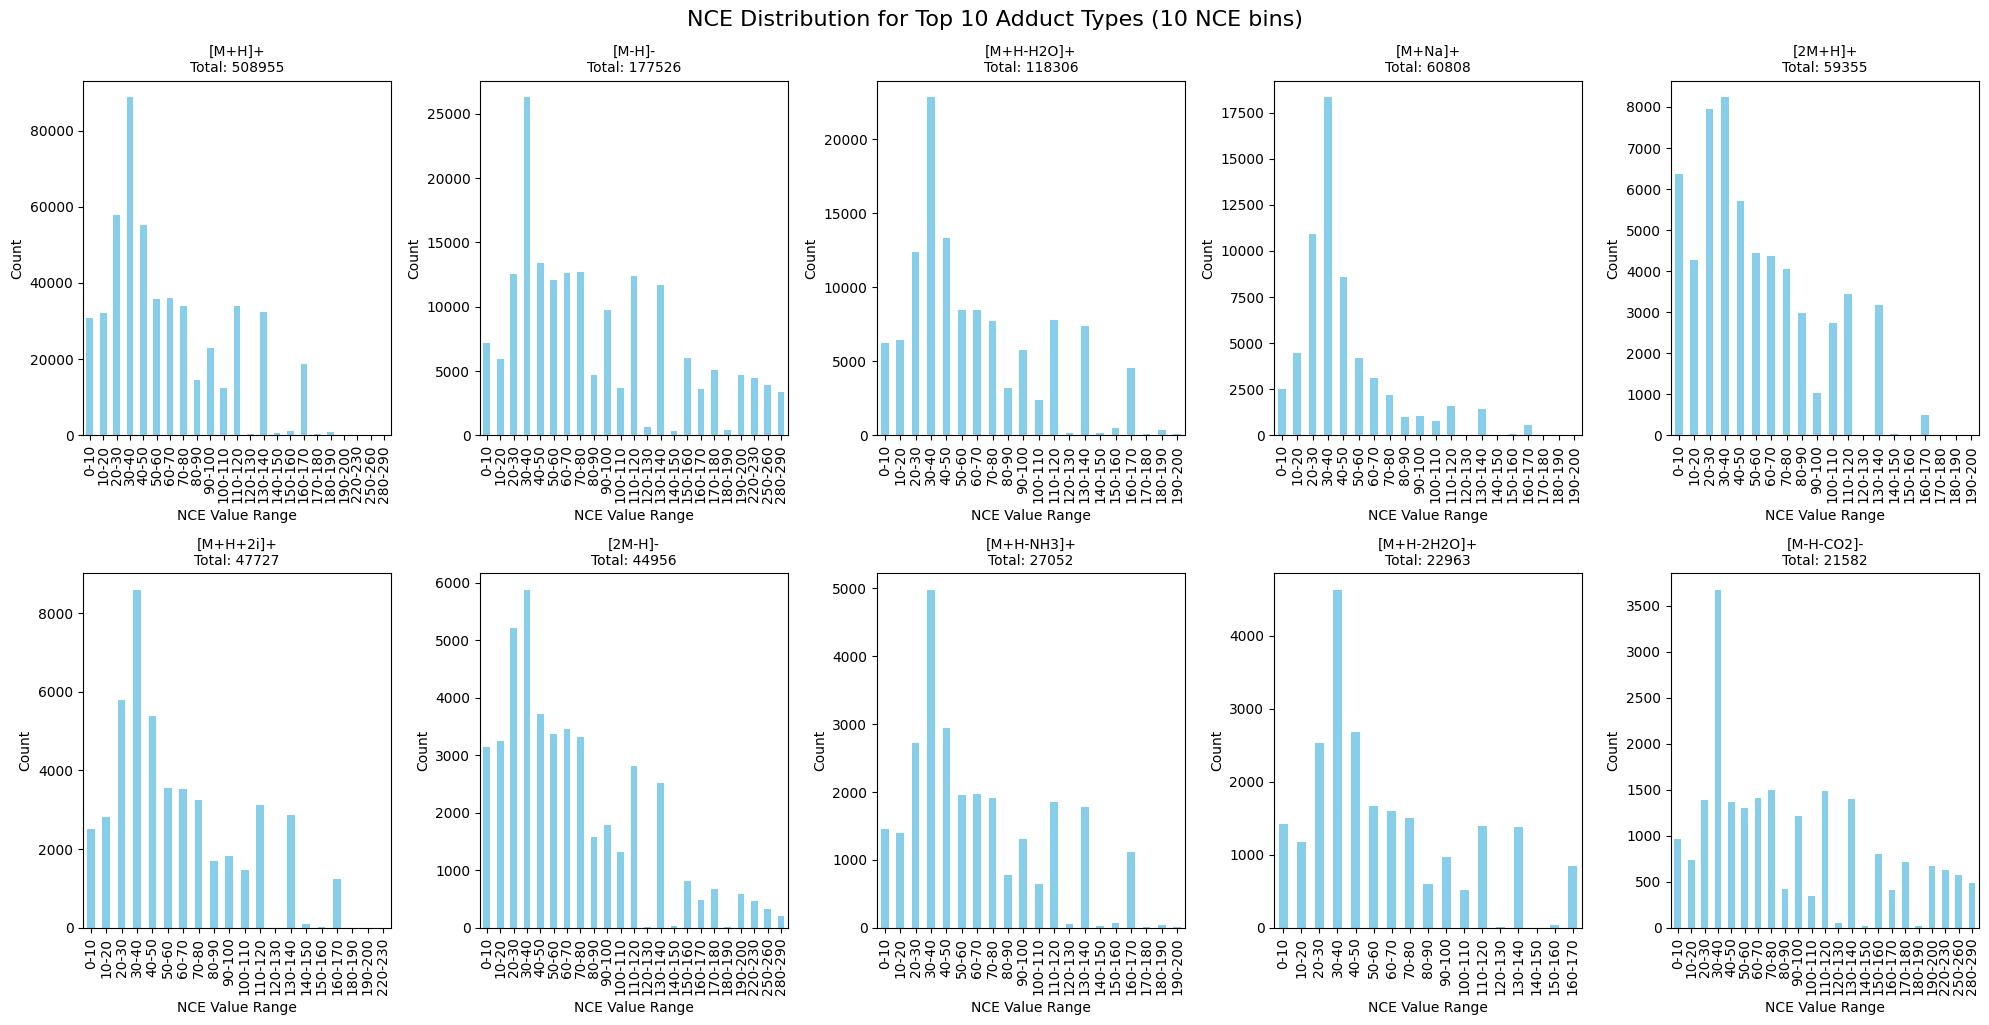

In [17]:
import numpy as np

prec_type_nce_counts = nist_spectra_df.groupby(['prec_type', 'nce']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_nce_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(10).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(20, 10), sharey=False)
axes = axes.flatten()

# Define NCE bins
nce_bin_size = 10
bins = np.arange(0, 325, nce_bin_size)
bin_labels = [f"{b}-{b+nce_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    nce_data = prec_type_nce_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in nce_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += nce_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('NCE Value Range')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'NCE Distribution for Top 10 Adduct Types ({nce_bin_size} NCE bins)', fontsize=16, y=1.02)
plt.show()

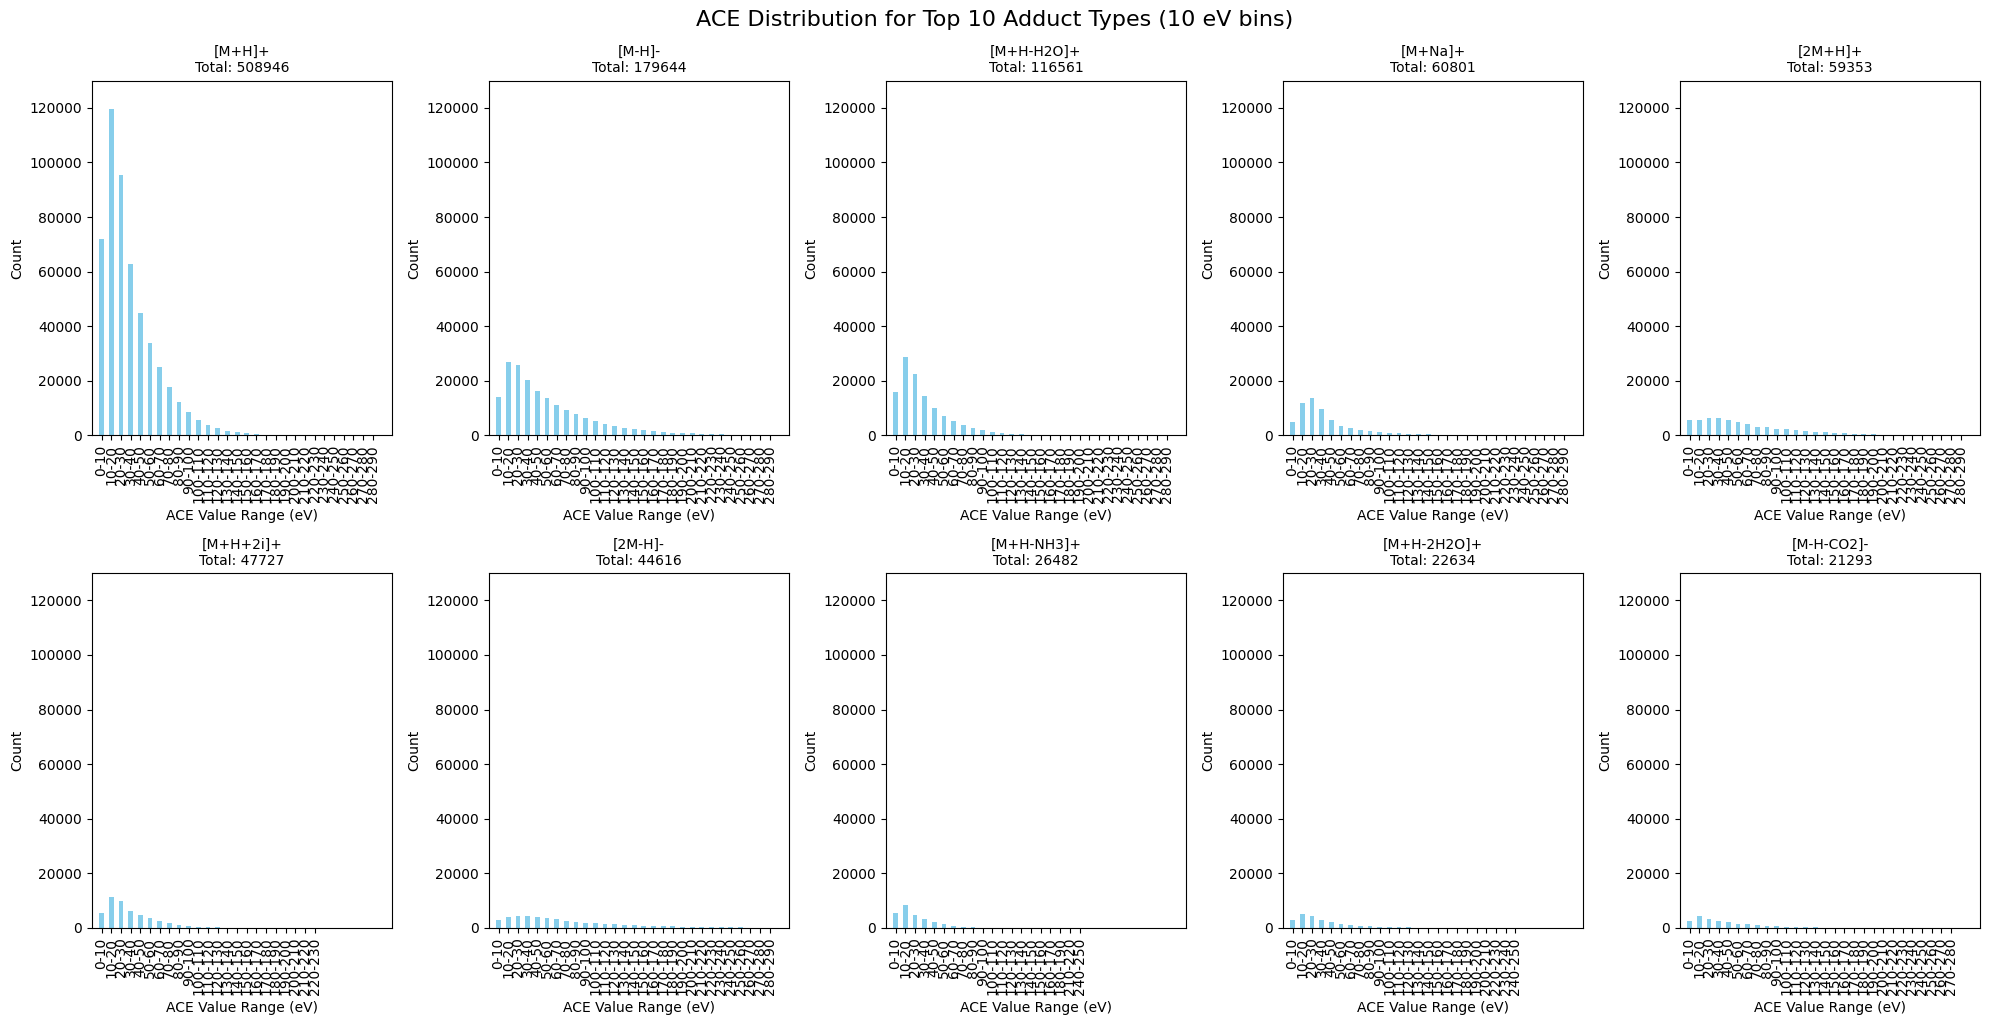

In [15]:
import numpy as np

prec_type_ace_counts = nist_spectra_df.groupby(['prec_type', 'ace']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_ace_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(10).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(20, 10), sharey=False)
axes = axes.flatten()

# Define ACE bins
ace_bin_size = 10
bins = np.arange(0, 300, ace_bin_size)
bin_labels = [f"{b}-{b+ace_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    ace_data = prec_type_ace_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in ace_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += ace_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('ACE Value Range (eV)')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylim(0, 130_000)
    ax.set_xlim(-1, 30)
    
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'ACE Distribution for Top 10 Adduct Types ({ace_bin_size} eV bins)', fontsize=16, y=1.02)
plt.show()

In [18]:
nist_mol_df = pd.read_pickle('../../data/proc/nist23/mol_df.pkl')
nist_mol_df.head()

,smiles,mol_id,mol,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,<rdkit.Chem.rdchem.Mol object at 0x7f53010f6b10>,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC(Br)(Br)c1cnc2ccccc2n1,1,<rdkit.Chem.rdchem.Mol object at 0x7f53010f6bb0>,VCCOPRMZNNMFLI,c1ccc2nccnc2c1,C9H5Br3N2,"InChI=1S/C9H5Br3N2/c10-9(11,12)8-5-13-6-3-1-2-...",380.865,377.800284,14,15,0,True,0
2,BrC1=CCCN(Cc2ccccc2)C1,2,<rdkit.Chem.rdchem.Mol object at 0x7f53010f6c50>,OFHMQSKRHZDSQE,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-7-4-8-14(10-12)9-11-...,252.155,251.030962,14,15,0,True,0
3,BrC1=CCN(Cc2ccccc2)CC1,3,<rdkit.Chem.rdchem.Mol object at 0x7f52fb79fb50>,PMICKOYXYJSXPC,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-6-8-14(9-7-12)10-11-...,252.155,251.030962,14,15,0,True,0
4,BrC1CCCCCC(Br)C12OCCO2,4,<rdkit.Chem.rdchem.Mol object at 0x7f53020913f0>,OQCIVOUQHXUSEL,C1CCCC2(CCC1)OCCO2,C10H16Br2O2,InChI=1S/C10H16Br2O2/c11-8-4-2-1-3-5-9(12)10(8...,328.044,325.951704,14,15,0,True,0


In [19]:
nist_df = nist_spectra_df.merge(nist_mol_df, on='mol_id', how='left')

nist_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,0,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461655,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0
1,1,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461656,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0
2,2,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461657,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0
3,3,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461658,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0
4,4,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461659,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0


Top 15 adduct types by unique molecules across instrument types:


inst_type,FT,QTOF
prec_type,,
[M+H]+,38244.0,1938.0
[M-H]-,16107.0,187.0
[M+H-H2O]+,9725.0,286.0
[M+Na]+,8640.0,128.0
[2M+H]+,4963.0,240.0
[2M-H]-,4149.0,65.0
[M+H+2i]+,4018.0,0.0
[M-H-CO2]-,2443.0,0.0
[M+H-NH3]+,2326.0,46.0


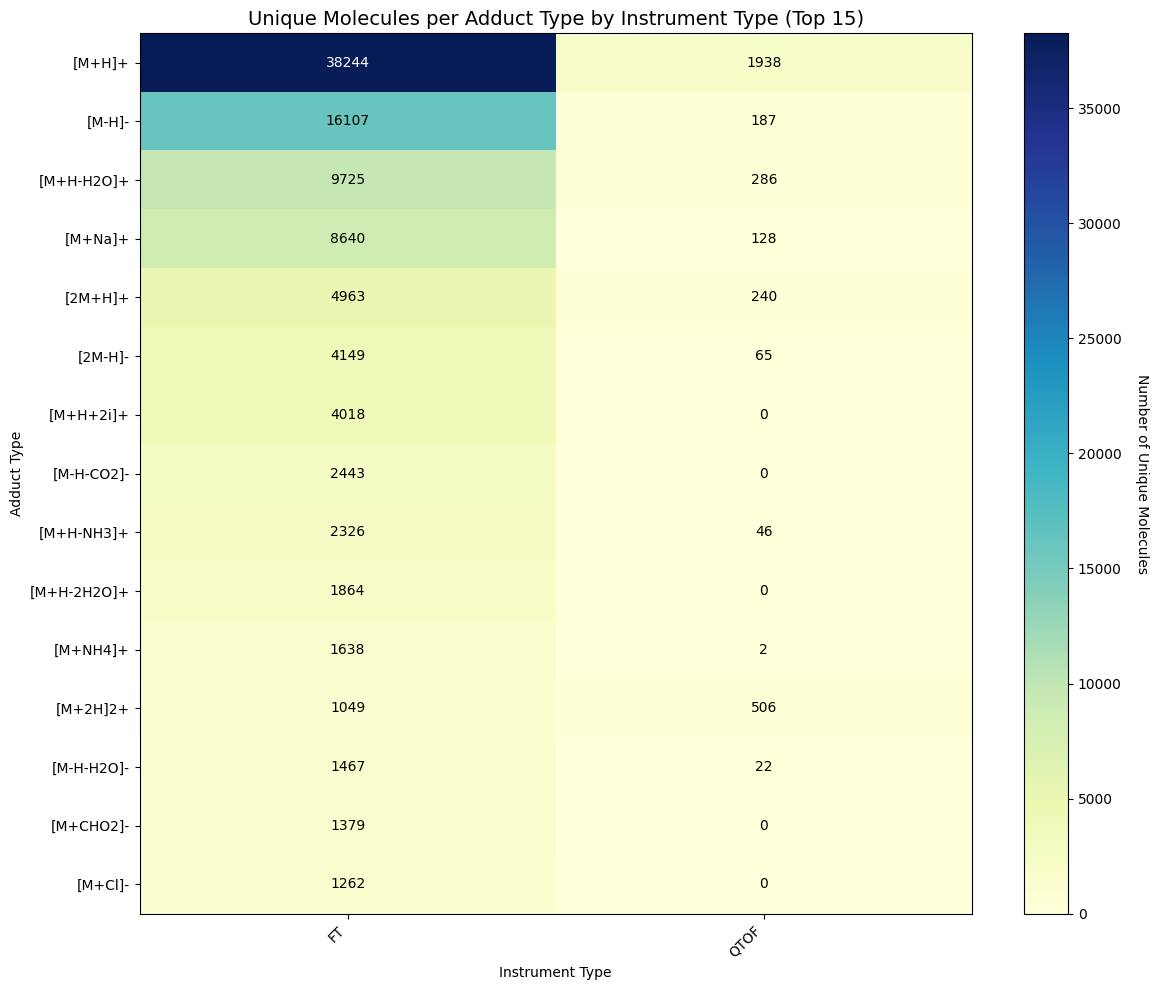


Summary:
Total unique adduct types: 27022
Total unique instrument types: 2

Instrument types available:
  FT: 186,515.0 unique molecules
  QTOF: 3,535.0 unique molecules


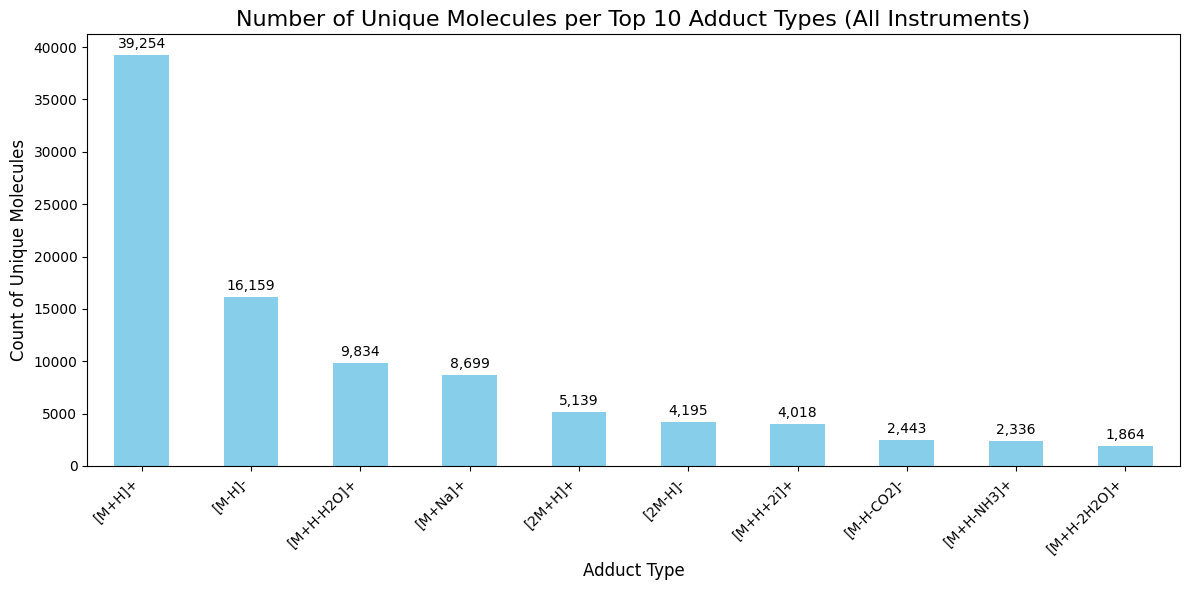

Number of unique molecules per adduct type (total across all instruments):
prec_type
[M+H]+         39254
[M-H]-         16159
[M+H-H2O]+      9834
[M+Na]+         8699
[2M+H]+         5139
[2M-H]-         4195
[M+H+2i]+       4018
[M-H-CO2]-      2443
[M+H-NH3]+      2336
[M+H-2H2O]+     1864
Name: mol_id, dtype: int64


In [22]:
# Calculate the number of unique molecules per each adduct type and instrument type
unique_mols_per_adduct_inst = nist_df.groupby(['prec_type', 'inst_type'])['mol_id'].nunique().reset_index(name='unique_mols')

# Create a pivot table for better visualization
mols_pivot = unique_mols_per_adduct_inst.pivot_table(index='prec_type', columns='inst_type', values='unique_mols', fill_value=0)

# Get the total unique molecules per adduct type across all instruments
total_by_adduct = mols_pivot.sum(axis=1).sort_values(ascending=False)
top_15_adducts = total_by_adduct.head(15).index

print("Top 15 adduct types by unique molecules across instrument types:")
print("="*70)
display(mols_pivot.loc[top_15_adducts])

# Create a matplotlib heatmap
fig, ax = plt.subplots(figsize=(12, 10))

# Select data for heatmap
heatmap_data = mols_pivot.loc[top_15_adducts]

# Create the heatmap using imshow
im = ax.imshow(heatmap_data.values, cmap='YlGnBu', aspect='auto')

# Set ticks and labels
ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_xticklabels(heatmap_data.columns, rotation=45, ha='right')
ax.set_yticklabels(heatmap_data.index)

# Add text annotations
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        text = ax.text(j, i, int(heatmap_data.iloc[i, j]),
                      ha="center", va="center", 
                      color="white" if heatmap_data.iloc[i, j] > heatmap_data.values.max()/2 else "black")

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Number of Unique Molecules', rotation=270, labelpad=20)

# Set labels and title
ax.set_title('Unique Molecules per Adduct Type by Instrument Type (Top 15)', fontsize=14)
ax.set_xlabel('Instrument Type')
ax.set_ylabel('Adduct Type')

plt.tight_layout()
plt.show()

# Show summary statistics
print(f"\nSummary:")
print(f"Total unique adduct types: {len(mols_pivot)}")
print(f"Total unique instrument types: {len(mols_pivot.columns)}")
print(f"\nInstrument types available:")
for inst_type in mols_pivot.columns:
    total_unique_mols = mols_pivot[inst_type].sum()
    print(f"  {inst_type}: {total_unique_mols:,} unique molecules")

# Calculate the number of unique molecules per each adduct type (total across all instruments)
unique_mols_per_adduct = nist_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 10 adduct types by number of unique molecules
top_10_adducts_by_mols = unique_mols_per_adduct.head(10)

# Create a bar plot for overall ranking
plt.figure(figsize=(12, 6))
top_10_adducts_by_mols.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 10 Adduct Types (All Instruments)', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_10_adducts_by_mols):
    plt.text(i, v + 0.01*max(top_10_adducts_by_mols), f"{v:,}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per adduct type (total across all instruments):")
print(top_10_adducts_by_mols)

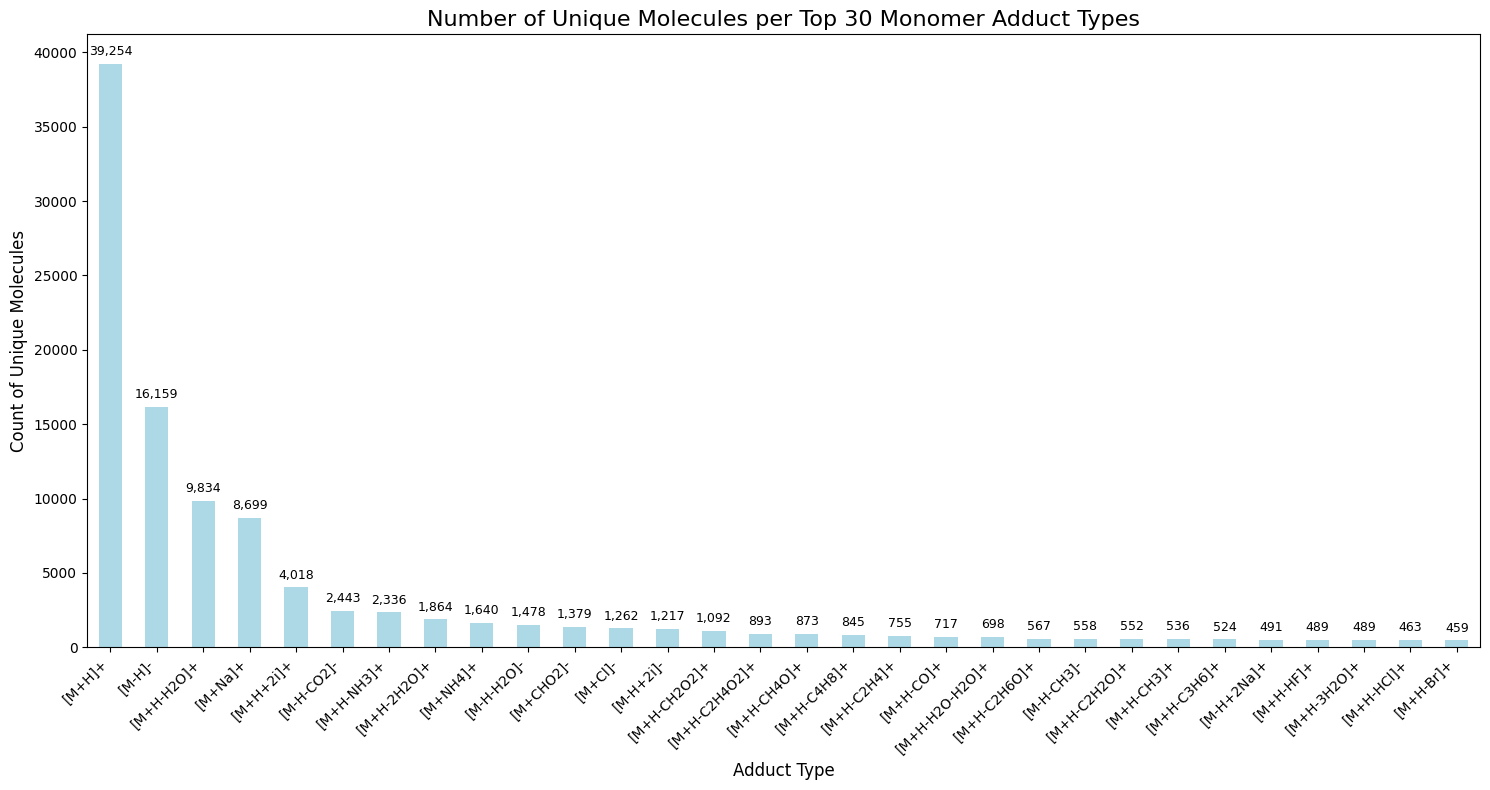

Number of unique molecules per monomer adduct type:
prec_type
[M+H]+            39254
[M-H]-            16159
[M+H-H2O]+         9834
[M+Na]+            8699
[M+H+2i]+          4018
[M-H-CO2]-         2443
[M+H-NH3]+         2336
[M+H-2H2O]+        1864
[M+NH4]+           1640
[M-H-H2O]-         1478
[M+CHO2]-          1379
[M+Cl]-            1262
[M-H+2i]-          1217
[M+H-CH2O2]+       1092
[M+H-C2H4O2]+       893
[M+H-CH4O]+         873
[M+H-C4H8]+         845
[M+H-C2H4]+         755
[M+H-CO]+           717
[M+H-H2O-H2O]+      698
[M+H-C2H6O]+        567
[M-H-CH3]-          558
[M+H-C2H2O]+        552
[M+H-CH3]+          536
[M+H-C3H6]+         524
[M-H+2Na]+          491
[M+H-HF]+           489
[M+H-3H2O]+         489
[M+H-HCl]+          463
[M+H-Br]+           459
Name: mol_id, dtype: int64


In [ ]:
# Filter out dimer adducts (those containing '2M') and multi-charge adducts
monomer_df = nist_df[
    (~nist_df['prec_type'].str.contains('2M')) & 
    (~nist_df['prec_type'].str.contains(']2+')) & 
    (~nist_df['prec_type'].str.contains(']2-')) & 
    (~nist_df['prec_type'].str.contains(']3+')) & 
    (~nist_df['prec_type'].str.contains(']3-'))
]

# Calculate the number of unique molecules per each adduct type (excluding dimers)
unique_mols_per_monomer_adduct = monomer_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 30 adduct types by number of unique molecules
top_30_monomer_adducts = unique_mols_per_monomer_adduct.head(30)

# Create a bar plot
plt.figure(figsize=(15, 8))
top_30_monomer_adducts.plot(kind='bar', color='lightblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 30 Monomer Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_30_monomer_adducts):
    plt.text(i, v + 0.01*max(top_30_monomer_adducts), f"{v:,}", 
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per monomer adduct type:")
print(top_30_monomer_adducts)

In [ ]:
import ms_entropy as me
import numpy as np
from tqdm.notebook import tqdm

print("Calculating spectral entropy...")
#peaks_query = np.array(spectraverse_spec_df.iloc[0]['peaks'])
#me.calculate_spectral_entropy(peaks_query, clean_spectrum = True, min_ms2_difference_in_da = 0.05)

tqdm.pandas(desc="Processing")
nist_spectra_df['ms_entropy'] = nist_spectra_df['peaks'].progress_apply(
    lambda peaks: me.calculate_spectral_entropy(
        np.array(peaks), clean_spectrum=True, min_ms2_difference_in_da=0.05
    )
)

Calculating spectral entropy...


Processing:   0%|          | 0/1754467 [00:00<?, ?it/s]

/tmp/ipykernel_1641245/2664503050.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nist_spectra_df['ms_entropy'] = nist_spectra_df['peaks'].progress_apply(


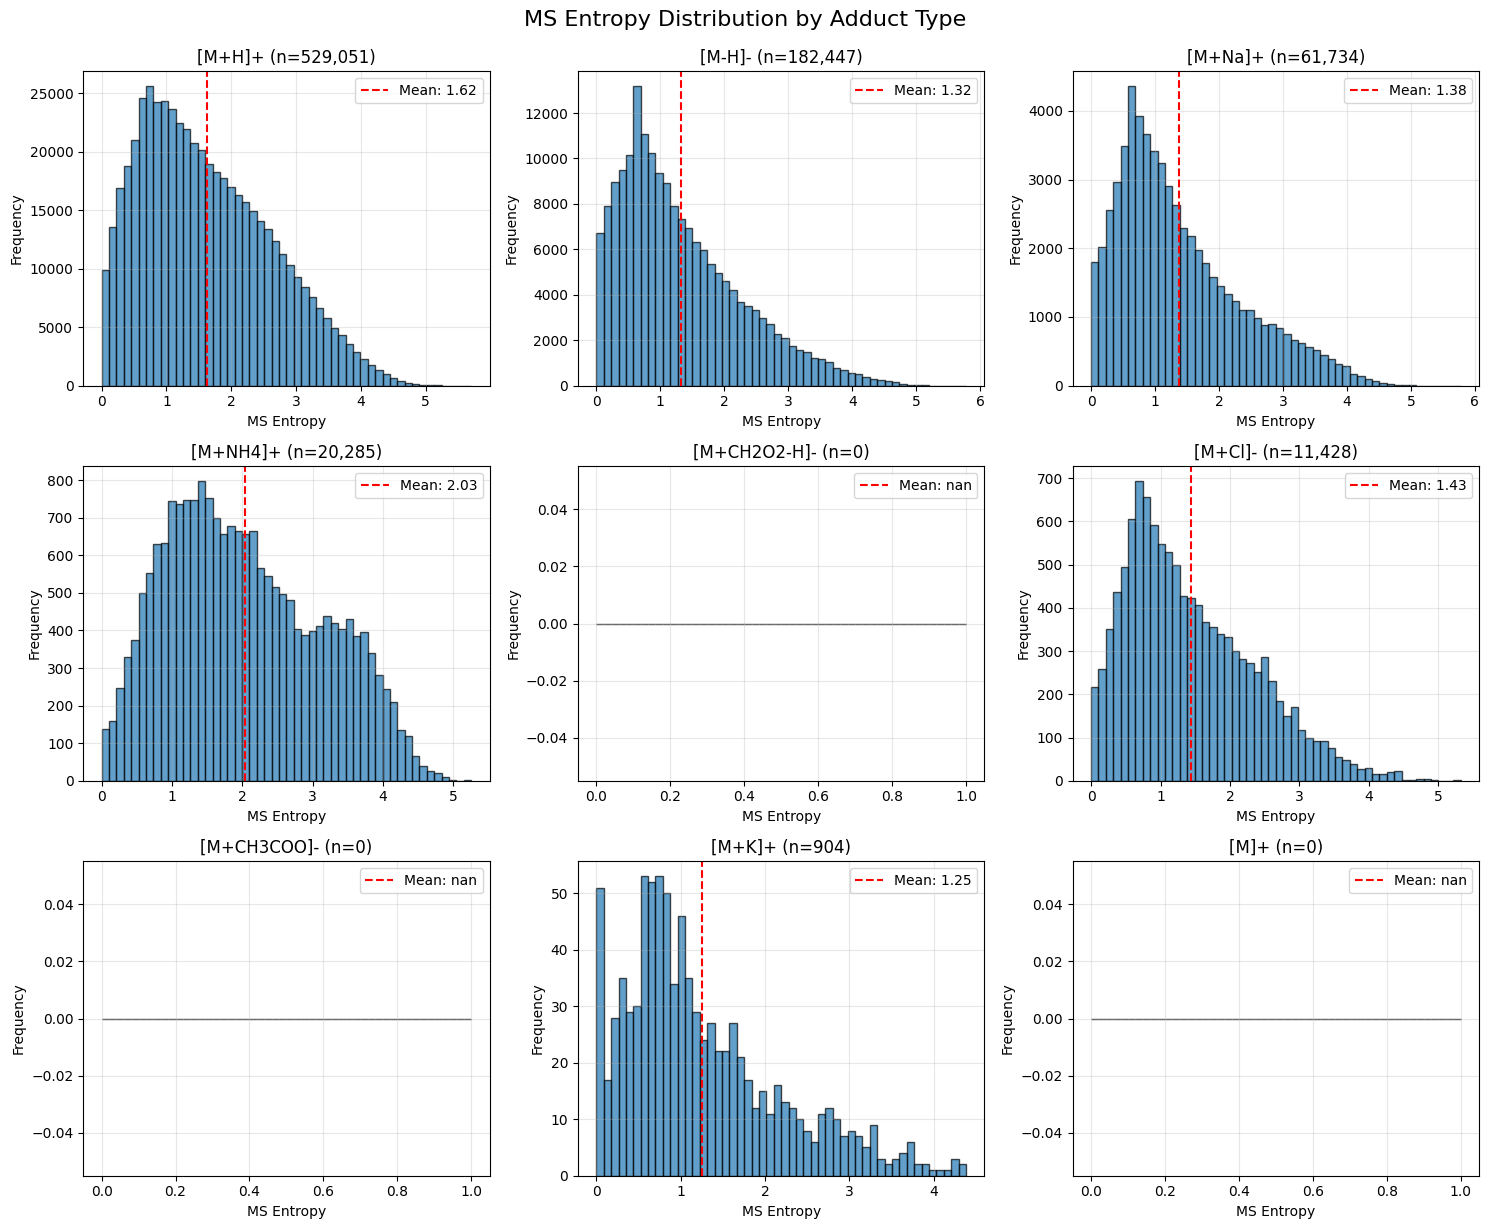

MS Entropy Statistics by Adduct Type:
--------------------------------------------------
[M+H]+      : Mean=1.624, Std=1.004, Median=1.467, Count=529,051
[M-H]-      : Mean=1.319, Std=0.950, Median=1.092, Count=182,447
[M+Na]+     : Mean=1.380, Std=0.965, Median=1.134, Count=61,734
[M+NH4]+    : Mean=2.033, Std=1.089, Median=1.893, Count=20,285
[M+CH2O2-H]-: Mean=nan, Std=nan, Median=nan, Count=0
[M+Cl]-     : Mean=1.434, Std=0.916, Median=1.239, Count=11,428
[M+CH3COO]- : Mean=nan, Std=nan, Median=nan, Count=0
[M+K]+      : Mean=1.247, Std=0.930, Median=0.998, Count=904
[M]+        : Mean=nan, Std=nan, Median=nan, Count=0


In [ ]:
# Create subplots for entropy distribution by adduct type
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

top_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+CH2O2-H]-', '[M+Cl]-', '[M+CH3COO]-', '[M+K]+', '[M]+']

for i, adduct in enumerate(top_adducts):
    adduct_data = nist_spectra_df[nist_spectra_df['prec_type'] == adduct]['ms_entropy']
    
    axes[i].hist(adduct_data, bins=50, alpha=0.7, edgecolor='black')
    axes[i].set_title(f'{adduct} (n={len(adduct_data):,})')
    axes[i].set_xlabel('MS Entropy')
    axes[i].set_ylabel('Frequency')
    axes[i].grid(True, alpha=0.3)
    
    # Add mean line
    mean_entropy = adduct_data.mean()
    axes[i].axvline(mean_entropy, color='red', linestyle='--', 
                   label=f'Mean: {mean_entropy:.2f}')
    axes[i].legend()

plt.tight_layout()
plt.suptitle('MS Entropy Distribution by Adduct Type', fontsize=16, y=1.02)
plt.show()

# Print summary statistics
print("MS Entropy Statistics by Adduct Type:")
print("-" * 50)
for adduct in top_adducts:
    adduct_data = nist_spectra_df[nist_spectra_df['prec_type'] == adduct]['ms_entropy']
    print(f"{adduct:12s}: Mean={adduct_data.mean():.3f}, Std={adduct_data.std():.3f}, "
          f"Median={adduct_data.median():.3f}, Count={len(adduct_data):,}")

In [ ]:
nist_spectra_df['num_peaks'] = nist_spectra_df['peaks'].apply(lambda x: len(x))

/tmp/ipykernel_1641245/3897027778.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nist_spectra_df['num_peaks'] = nist_spectra_df['peaks'].apply(lambda x: len(x))


/tmp/ipykernel_1641245/2104158102.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


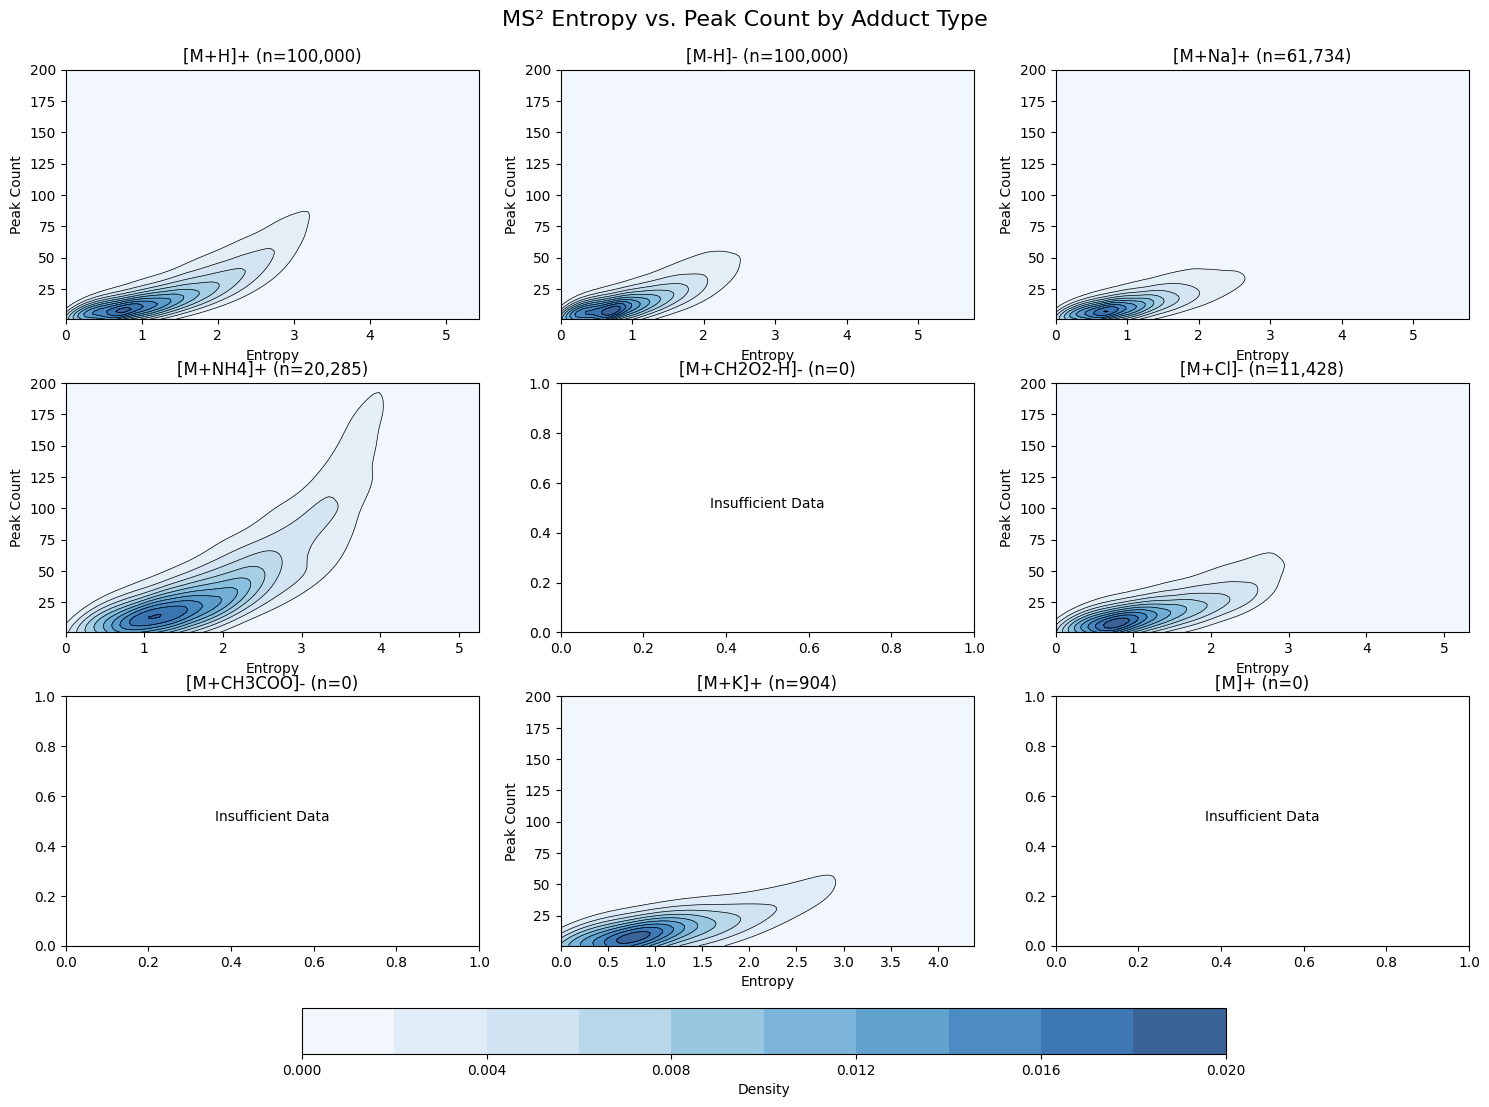

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

top_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+CH2O2-H]-', '[M+Cl]-', '[M+CH3COO]-', '[M+K]+', '[M]+']

contourf_handles = []

for i, adduct in enumerate(top_adducts):
    adduct_data = nist_spectra_df[nist_spectra_df['prec_type'] == adduct]
    sampled_df = adduct_data.sample(n=min(100_000, len(adduct_data)))
    entropy = sampled_df['ms_entropy'].values
    peak_num = sampled_df['num_peaks'].values

    if len(entropy) < 2:
        axes[i].text(0.5, 0.5, 'Insufficient Data', ha='center')
        axes[i].set_title(f'{adduct} (n={len(sampled_df)})')
        continue

    values = np.vstack([entropy, peak_num])
    kernel = gaussian_kde(values)

    x_min, x_max = entropy.min(), entropy.max()
    y_min, y_max = peak_num.min(), min(peak_num.max(), 200)
    X, Y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    positions = np.vstack([X.ravel(), Y.ravel()])
    Z = np.reshape(kernel(positions).T, X.shape)

    levels = 10
    cf = axes[i].contourf(X, Y, Z, levels=levels, cmap='Blues', alpha=0.8)
    axes[i].contour(X, Y, Z, levels=levels, colors='black', linewidths=0.5)
    axes[i].set_xlabel('Entropy')
    axes[i].set_ylabel('Peak Count')
    axes[i].set_title(f'{adduct} (n={len(sampled_df):,})')
    axes[i].set_ylim(y_min, y_max)
    contourf_handles.append(cf)

# Add a single colorbar for the last contourf plot
cbar = fig.colorbar(contourf_handles[-1], ax=axes, orientation='horizontal', fraction=0.05, pad=0.01)
cbar.set_label('Density')

plt.tight_layout()
plt.subplots_adjust(top=0.93, bottom=0.2)  # Adjust bottom as needed
fig.suptitle('MS² Entropy vs. Peak Count by Adduct Type', fontsize=16)
plt.show()